# H5 — Self-healing landing and classical replanning

Run the **same timestamped faults** under the original target and event-triggered replanning.
The physical state is propagated from H4; fuel, thrust and the absolute touchdown deadline are preserved.
The notebook uses the repository model and makes **zero quantum/provider calls**.

This is a bounded nonrotating **2D simulation**. Hazards are declared landing exclusion intervals,
not newly downloaded terrain or volumetric collision geometry. The synthetic examples are not NASA
flight telemetry, flight-qualified recovery or evidence of quantum advantage.

In [1]:
from pathlib import Path
from copy import deepcopy
from html import escape
import json
import os
import sys
from IPython.display import HTML, SVG, display
start = Path(os.environ.get("LUNAR_REPO_ROOT", Path.cwd())).resolve()
roots = [start, *start.parents, start / "quantum-hybrid-workspace", start / "h0-hybrid-workspace"]
ROOT = next((p for p in roots if (p / "backend/app/self_healing.py").is_file()), None)
if ROOT is None:
    raise RuntimeError("Open from the repository or set LUNAR_REPO_ROOT.")
sys.path.insert(0, str(ROOT))
from backend.app.self_healing import RecoveryScenario, compare_recovery, replay_recovery
import backend.app.self_healing as recovery_module
assert Path(recovery_module.__file__).resolve() == ROOT / "backend/app/self_healing.py"
def table(headers, rows):
    def row(values, tag):
        return "<tr>" + "".join(f"<{tag}>{escape(str(v))}</{tag}>" for v in values) + "</tr>"
    display(HTML("<table>" + row(headers,"th") + "".join(row(r,"td") for r in rows) + "</table>"))
raw = json.loads((ROOT / "shared/examples/recovery/combined_recovery.json").read_text())
job = RecoveryScenario.model_validate(raw)
print("Explicit frame:", job.initial_request.initial_state.reference_frame)
print("Scenario:", job.scenario_id, "seed:", job.seed, "uncertainty samples per candidate:", job.uncertainty.samples)
table(["Event UTC", "Sequence", "Effect"], [[e.epoch_utc.isoformat(), e.sequence, e.payload.model_dump()] for e in job.events])

Explicit frame: PLANAR_MOON_CENTERED_NONROTATING
Scenario: h5-combined-recovery seed: 17 uncertainty samples per candidate: 8


Event UTC,Sequence,Effect
2030-01-01T00:00:05+00:00,0,"{'kind': 'propellant_loss', 'amount_kg': 3.0}"
2030-01-01T00:00:05+00:00,1,"{'kind': 'thrust_loss', 'available_thrust_n': 3000.0}"
2030-01-01T00:00:05+00:00,2,"{'kind': 'landing_hazard', 'start_downrange_m': -5.0, 'end_downrange_m': 5.0}"


## 1. Original target versus recovery

At 5 seconds the vehicle loses 3 kg of propellant, its thrust ceiling falls to 3000 N, and
landing between −5 m and +5 m downrange becomes prohibited. The backup is at +40 m.
Both branches receive identical exogenous events. The baseline retains the original target;
recovery first checks whether that target is still valid, then checks the alternatives.

In [2]:
comparison = compare_recovery(job)
baseline, recovered = comparison["baseline"], comparison["recovery"]
assert baseline["status"] == "failed" and "landing_hazard" in baseline["final_reasons"]
assert recovered["status"] == "landed" and recovered["selected_target_id"] == "backup"
table(["Mode", "Status", "Target", "Remaining fuel (kg)", "Reasons"], [
    [r["mode"], r["status"], r["selected_target_id"], round(r["final_state"]["propellant_kg"],6), ", ".join(r["final_reasons"])]
    for r in (baseline, recovered)
])
print("Recovery balance (kg): burned + lost + remaining =", recovered["propellant_burned_kg"], "+", recovered["propellant_lost_kg"], "+", recovered["final_state"]["propellant_kg"])
assert abs(recovered["propellant_burned_kg"] + recovered["propellant_lost_kg"] + recovered["final_state"]["propellant_kg"] - 100) < 1e-8

Mode,Status,Target,Remaining fuel (kg),Reasons
fixed_original_target,failed,primary,79.784004,landing_hazard
classical_replanning,landed,backup,79.666978,


Recovery balance (kg): burned + lost + remaining = 17.3330218296029 + 3.0 + 79.6669781703971


## 2. Inspect the exact event boundary

The integrator pauses at the event timestamp instead of selecting the nearest stored sample.
Events sharing a timestamp use their explicit sequence number. Every applied event increments
the state revision. The event log preserves before/after truth and the synthetic observation.

In [3]:
table(["Event", "UTC", "Revision", "Fuel before / after (kg)", "Thrust ceiling (N)"], [
    [e["event_id"], e["before"]["epoch_utc"], e["after"]["revision"],
     (round(e["before"]["propellant_kg"],6), round(e["after"]["propellant_kg"],6)), e["available_thrust_n"]]
    for e in recovered["event_log"]
])
assert [e["after"]["revision"] for e in recovered["event_log"]] == [1, 2, 3]
assert all(e["before"]["epoch_utc"] == "2030-01-01T00:00:05Z" for e in recovered["event_log"])

Event,UTC,Revision,Fuel before / after (kg),Thrust ceiling (N)
fuel-loss,2030-01-01T00:00:05Z,1,"(97.550931, 94.550931)",10000.0
thrust-loss,2030-01-01T00:00:05Z,2,"(94.550931, 94.550931)",3000.0
primary-blocked,2030-01-01T00:00:05Z,3,"(94.550931, 94.550931)",3000.0


## 3. Why was the backup selected?

A candidate must satisfy the nominal H4 flight limits at two integration resolutions,
pass numerical agreement, and pass **every supplied Monte Carlo draw**. All candidates share
the same draws. The current target is retained when valid; otherwise the accepted candidate
with least nominal predicted fuel use is selected.

The default example has zero uncertainty, so its eight draws repeat the same limit case.
Later cells introduce nonzero uncertainty. Passing eight draws is not a safety probability.

In [4]:
last_decision = recovered["decisions"][-1]
table(["Candidate", "Accepted", "Coarse / fine feasible", "Uncertainty passes", "Reasons"], [
    [c["target_id"], c["accepted"], (c["coarse_feasible"],c["fine_feasible"]),
     f'{c["uncertainty"]["pass_count"]}/{c["uncertainty"]["sample_count"]}', ", ".join(c["reasons"])]
    for c in last_decision["candidates"]
])
print("Decision:", last_decision["action"], "revision:", last_decision["revision"])
print("Decision fingerprint:", last_decision["input_sha256"])
assert last_decision["action"] == "retarget"

Candidate,Accepted,Coarse / fine feasible,Uncertainty passes,Reasons
backup,True,"(True, True)",8/8,
primary,False,"(False, False)",0/0,landing_hazard


Decision: retarget revision: 3
Decision fingerprint: b18d4d741fba8d76215d79dcc0c28ebbd4d667515434b9041dd2db4ff167d27c


## 4. Compare trajectories

The chart reads the stored trace. It does not run a second solver. Red keeps the original
zero-downrange target; blue diverts to +40 m after the fault boundary. The vehicle still has
to meet the same absolute touchdown deadline and reserve limit.

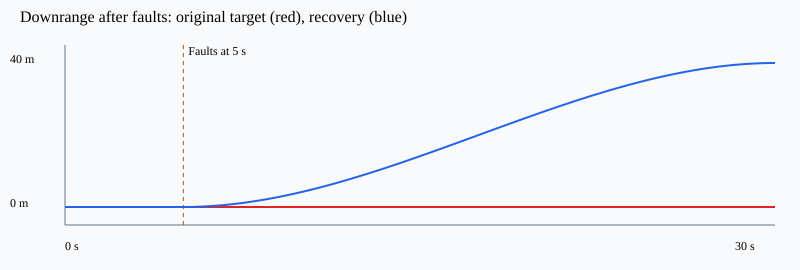

In [5]:
width, height = 800, 270
left, right, top, bottom = 65, 775, 45, 225
x = lambda t: left + t / 30 * (right-left)
y = lambda d: bottom - (d+5) / 50 * (bottom-top)
paths = []
for run, color in ((baseline,"#dc2626"),(recovered,"#2563eb")):
    points = " ".join(f'{x(r["elapsed_s"]):.3f},{y(r["downrange_m"]):.3f}' for r in run["trace"])
    paths.append(f'<polyline points="{points}" fill="none" stroke="{color}" stroke-width="2"/>')
display(SVG(f'<svg xmlns="http://www.w3.org/2000/svg" width="{width}" height="{height}"><rect width="100%" height="100%" fill="#f8fafc"/><text x="20" y="22" font-size="16">Downrange after faults: original target (red), recovery (blue)</text><line x1="{left}" y1="{bottom}" x2="{right}" y2="{bottom}" stroke="#64748b"/><line x1="{left}" y1="{top}" x2="{left}" y2="{bottom}" stroke="#64748b"/><line x1="{x(5)}" y1="{top}" x2="{x(5)}" y2="{bottom}" stroke="#b45309" stroke-dasharray="4 4"/><text x="{x(5)+5}" y="55" font-size="12">Faults at 5 s</text><text x="10" y="{y(40)}" font-size="12">40 m</text><text x="10" y="{y(0)}" font-size="12">0 m</text><text x="{left}" y="250" font-size="12">0 s</text><text x="735" y="250" font-size="12">30 s</text>{"".join(paths)}</svg>'))

## 5. Show unrecoverable cases

An empty tank or a fully failed engine cannot be made feasible by changing an optimizer.
If no candidate passes, recovery stops at the decision boundary and returns
`no_feasible_continuation`. It does **not** claim that the vehicle has safely aborted,
landed or stopped moving in reality. No unvalidated fallback is flown.

In [6]:
engine_raw = json.loads((ROOT / "shared/examples/recovery/engine_out.json").read_text())
engine_case = compare_recovery(RecoveryScenario.model_validate(engine_raw))
fuel_raw = deepcopy(engine_raw)
fuel_raw["scenario_id"] = "h5-empty-tank"
fuel_raw["events"][0]["payload"] = {"kind":"propellant_loss", "amount_kg":1000.}
fuel_case = compare_recovery(RecoveryScenario.model_validate(fuel_raw))
for c in (engine_case, fuel_case):
    assert c["recovery"]["status"] == "infeasible"
    assert c["recovery"]["selected_target_id"] is None
table(["Fault", "Original target", "Recovery verdict", "Decision UTC"], [
    [name, c["baseline"]["status"], c["recovery"]["decisions"][-1]["action"], c["recovery"]["final_state"]["epoch_utc"]]
    for name,c in (("Engine out",engine_case),("Empty tank",fuel_case))
])

Fault,Original target,Recovery verdict,Decision UTC
Engine out,failed,no_feasible_continuation,2030-01-01T00:00:05Z
Empty tank,failed,no_feasible_continuation,2030-01-01T00:00:05Z


## 6. Keep truth separate from what the planner sees

A sensor fault introduces a seeded, persistent additive bias in planar Cartesian position/velocity.
The identity estimator uses the synthetic observation as its estimate; it does not read ground truth
to correct that estimate. Candidate evaluation samples possible true states around the estimate
and uses the opposite fixed bias so guidance still sees the declared estimate.

This is an explicit simplified observation model, not a Kalman filter or a calibrated sensor model.

In [7]:
sensor_raw = deepcopy(engine_raw)
sensor_raw["scenario_id"] = "h5-degraded-navigation"
sensor_raw["events"][0]["payload"] = {"kind":"sensor_degradation", "sensor_id":"landing-nav", "position_std_m":[30.,0.], "velocity_std_mps":[0.,0.]}
sensor_run = replay_recovery(RecoveryScenario.model_validate(sensor_raw))
evidence = sensor_run["event_log"][0]
assert evidence["before"]["position_m"] == evidence["after"]["position_m"]
assert evidence["estimated_after"]["position_m"] != evidence["after"]["position_m"]
table(["Record", "Position (m)", "Meaning"], [
    ["Truth", evidence["after"]["position_m"], "Physical state, unchanged by the sensor fault"],
    ["Observation", evidence["observation"]["position_m"], "Synthetic noisy sensor output"],
    ["Estimate", evidence["estimated_after"]["position_m"], "Planner input; identity estimator"],
])
table(["Candidate", "Sample passes", "Failure causes"], [
    [c["target_id"], f'{c["uncertainty"]["pass_count"]}/{c["uncertainty"]["sample_count"]}', c["uncertainty"]["failure_counts"]]
    for c in sensor_run["decisions"][-1]["candidates"]
])
assert sensor_run["status"] == "infeasible"

Record,Position (m),Meaning
Truth,"[0.0, 1737482.5131744016]","Physical state, unchanged by the sensor fault"
Observation,"[-10.830421651311363, 1737482.5131744016]",Synthetic noisy sensor output
Estimate,"[-10.830421651311363, 1737482.5131744016]",Planner input; identity estimator


Candidate,Sample passes,Failure causes
backup,1/8,"{'no_contact': 4, 'position': 3}"
primary,1/8,{'no_contact': 7}


## 7. Communication is an explicit policy constraint

An outage does not turn off physics. When retargeting requires a ground link, continuing a valid
current target is allowed but choosing another target is blocked during the half-open outage.
With explicit autonomous-retarget permission, the same vehicle can choose a validated backup.
This does not model DSN visibility, radio link budgets or station booking.

In [8]:
comm_raw = deepcopy(raw)
comm_raw["events"] = [deepcopy(raw["events"][-1])]
comm_raw["events"][0]["sequence"] = 1
outage = deepcopy(raw["events"][0])
outage.update(event_id="link-outage", sequence=0)
outage["payload"] = {"kind":"communication_outage", "end_utc":"2030-01-01T00:00:20Z"}
comm_raw["events"].append(outage)
blocked = replay_recovery(RecoveryScenario.model_validate(comm_raw))
comm_raw["require_link_for_retarget"] = False
autonomous = replay_recovery(RecoveryScenario.model_validate(comm_raw))
assert blocked["status"] == "infeasible" and autonomous["status"] == "landed"
table(["Policy", "Status", "Target"], [["Ground approval required",blocked["status"],blocked["selected_target_id"]], ["Autonomous retarget allowed",autonomous["status"],autonomous["selected_target_id"]]])

Policy,Status,Target
Ground approval required,infeasible,None
Autonomous retarget allowed,landed,backup


## 8. Repeat uncertainty experiments across seeds

Gaussian navigation errors and bounded uniform thrust/fuel shortfalls are declared assumptions.
The same draws are shared by candidates at each decision, keyed by scenario seed and revision.
We report sample success counts and failure causes, **not calibrated landing probabilities**.
Time-to-contact constraints can make nonzero navigation errors fail even for otherwise reachable sites.

In [9]:
seed_rows = []
for seed in (17,23,42):
    changed = deepcopy(sensor_raw)
    changed["seed"] = seed
    run = replay_recovery(RecoveryScenario.model_validate(changed))
    decision = run["decisions"][-1]
    seed_rows.append([seed, run["status"], [(c["target_id"],c["uncertainty"]["pass_count"],c["uncertainty"]["sample_count"]) for c in decision["candidates"]]])
table(["Seed", "Verdict", "Candidate sample passes / count"], seed_rows)

Seed,Verdict,Candidate sample passes / count
17,infeasible,"[('backup', 1, 8), ('primary', 1, 8)]"
23,infeasible,"[('backup', 0, 8), ('primary', 1, 8)]"
42,infeasible,"[('backup', 2, 8), ('primary', 2, 8)]"


## 9. Reproducibility and handoff

The scenario fingerprint includes model version and all validated inputs. Decision fingerprints
also identify state revision, estimate, current target, active hazards, thrust availability and
uncertainty. Event input order is canonicalized by UTC timestamp and sequence.

H5 is synchronous and assumes zero planning delay in simulated time. Budgets are bounded by
8 candidates, 8 events and 32 uncertainty draws; this is not a real-time deadline guarantee.
Targets retain absolute deadlines. Less than 5 seconds remaining is outside H4's supported
restart horizon and is rejected. A landing ends replay; later events remain explicitly unapplied.

H6 remains responsible for asynchronous quantum selection, stale-result rejection, validated
fallback deadlines and downstream multi-mission rescheduling. H4's sampled-terrain, planar and
ideal-engine limits still apply. A declared exclusion interval is not volumetric obstacle avoidance.

In [10]:
repeat = compare_recovery(job)
assert repeat == comparison
assert recovered["scenario_sha256"] == baseline["scenario_sha256"]
assert recovered["decisions"][0]["input_sha256"] != recovered["decisions"][-1]["input_sha256"]
print("Deterministic replay verified; scenario fingerprint:", recovered["scenario_sha256"])
print("Final recovery UTC:", recovered["final_state"]["epoch_utc"])
print("Notebook assertions passed. Quantum/provider calls: 0.")

Deterministic replay verified; scenario fingerprint: 1ce6c6abe6d71c4ac53ff25eccbd3dae3d5c7557853c7f7b400efb6853e2adaf
Final recovery UTC: 2030-01-01T00:00:29.999953Z
Notebook assertions passed. Quantum/provider calls: 0.
